In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:40983")
client

<Client: 'tcp://127.0.0.1:40983' processes=12 threads=48, memory=755.54 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [32]:
ds = xr.open_dataset(op.join(ddir,"MSQG/vars_0009.nc")
                    ).isel(time=slice(50,None)
                          ).chunk({"time":4,"level":1,"y":128,"x":256})
dsin = xr.open_dataset(op.join(ddir,"MSQG/input_vars_5l_N1024.nc")
                      ).isel(t=0).chunk({"z":1,"y":128,"x":256})
ds, dsin

(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
 Attributes:
     history:  Mon Sep 14 12:31:23 2026: ncrcat -O tmp_vars/vars_0015.nc tmp_v...
     NCO:      netCDF Operators version 5.1.9 (Homepage = http://nco.sf.net, C...,
 <xarray.Dataset> Size: 27MB
 Dimensions:  (z: 5, y: 513, x: 1025)
 Coordinates:
   * z        (z) float32 20B 0.0 1.0 2.0 3.

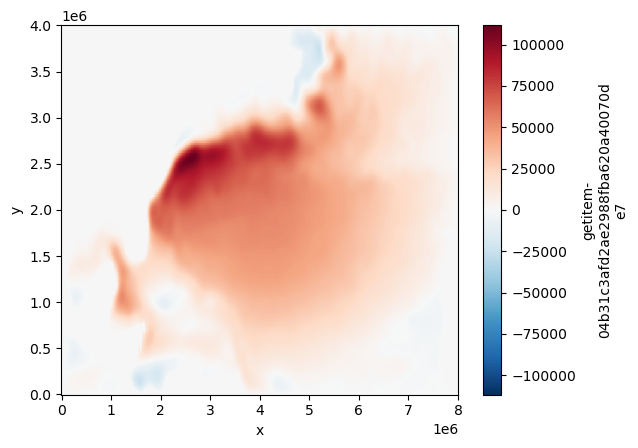

In [33]:
sshb = xr.DataArray(dsin.psi_pg.isel(z=0).data,
                   dims=["y","x"],
                   coords={"y":ds.y.data,"x":ds.x.data}
                  )
sshb.plot(rasterized=True)

In [6]:
dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":ds.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(Z,Zp1)

ds["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
ds["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":ds.level.data}
                       )
ds["N2"] = xr.DataArray(dsin.N2.data, dims=["level","y","x"],
                        coords=ds.psi.isel(time=0).coords)

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds, grid

[ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025, lp1: 6, yG: 512, xG: 1024)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 2kB 3.906e+03 1.172e+04 ... 3.988e+06 3.996e+06
   * xG       (xG) float32 4kB 3.906e+03 1.172e+04 ... 7.988e+06 7.996e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+0

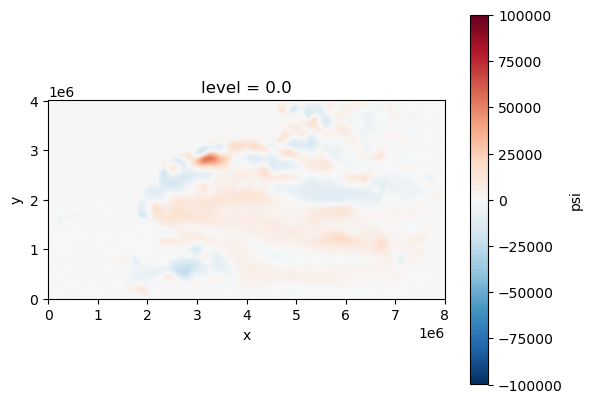

In [31]:
fig, ax = plt.subplots()
ds.psi.isel(level=0).mean("time").plot(ax=ax, rasterized=True, vmax=1e5)
ax.set_aspect("equal")

In [7]:
Delta = 3.90625e+03
u = -(grid.diff(ds.psi.fillna(0.).chunk({"y":-1}),"Y",padding="extend") 
       / Delta)
v = (grid.diff(ds.psi.fillna(0.).chunk({"x":-1}),"X",padding="extend") 
      / Delta)
f0 = 7.3e-05
beta = 2e-11
ff = f0 + beta*(ds.y-ds.y.mean())
b = (grid.diff(ds.psi.fillna(0.).chunk({"level":-1}),
               "Z",padding="extend")
     / grid.diff(ds.Z,"Z",padding="extend")
    ).isel(lp1=slice(1,-1)) * ff
b = xr.DataArray(xr.concat([xr.concat([xr.zeros_like(b.isel(lp1=0)),b], "lp1"),
                            xr.zeros_like(b.isel(lp1=-1))], "lp1"
                          ).data,
                 dims=["time","y","x","lp1"],
                 coords={"time":ds.time.data, "lp1":ds.lp1.data,
                         "y":ds.y.data, "x":ds.x.data}
                )
u, v, b

(<xarray.DataArray 'psi' (time: 297, level: 5, yG: 512, x: 1025)> Size: 3GB
 dask.array<neg, shape=(297, 5, 512, 1025), dtype=float32, chunksize=(4, 1, 512, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * yG       (yG) float32 2kB 3.906e+03 1.172e+04 ... 3.988e+06 3.996e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06,
 <xarray.DataArray 'psi' (time: 297, level: 5, y: 513, xG: 1024)> Size: 3GB
 dask.array<truediv, shape=(297, 5, 513, 1024), dtype=float32, chunksize=(4, 1, 128, 1024), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * xG       (xG) float32 4kB 3.906e+03 1.172e+04 ... 7.988e+06 7.996e+06,
 <xarray.DataArray 'concatena

In [9]:
E00 = (u**2).mean("time")
Ediag = grid.interp((b**2).mean("time").chunk({"lp1":-1}),
                    "Z",padding="extend")
E10 = (grid.interp(grid.interp(u.chunk({"x":-1}),
                               "X",padding="extend").chunk({"yG":-1}),
                   "Y",padding="extend")
       * v
      ).mean("time")
E01 = (u 
       * grid.interp(grid.interp(v.chunk({"xG":-1}),
                                 "X",padding="extend").chunk({"y":-1}),
                     "Y",padding="extend")
      ).mean("time")
E11 = (v**2).mean("time")
E20 = -(grid.interp(grid.interp(v.chunk({"xG":-1}),
                                "X",padding="extend").chunk({"level":-1}),
                    "Z",padding="extend")
        * b
       ).mean("time") * ff/grid.interp(ds.N2.chunk({"level":-1}),
                                       "Z",padding="extend")
E21 = (grid.interp(grid.interp(u.chunk({"yG":-1}),
                               "Y",padding="extend").chunk({"level":-1}),
                   "Z",padding="extend")
       * b
      ).mean("time") * ff/grid.interp(ds.N2.chunk({"level":-1}),
                                      "Z",padding="extend")

dsave = E00.to_dataset(name="E00")
dsave["Ediag"] = Ediag
dsave["E01"] = E01
dsave["E10"] = E10
dsave["E11"] = E11
dsave["E20"] = E20
dsave["E21"] = E21
print(dsave)
dsave.chunk({"level":1,"lp1":1,"y":128,"x":256,"yG":128,"xG":256}
           ).to_zarr(op.join(ddir,"MSQG/E-P.zarr"), mode="w")
dsave.close()

<xarray.Dataset> Size: 114MB
Dimensions:  (level: 5, x: 1025, yG: 512, y: 513, xG: 1024, lp1: 6)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
  * yG       (yG) float32 2kB 3.906e+03 1.172e+04 ... 3.988e+06 3.996e+06
  * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
  * xG       (xG) float32 4kB 3.906e+03 1.172e+04 ... 7.988e+06 7.996e+06
  * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
Data variables:
    E00      (level, yG, x) float32 10MB dask.array<chunksize=(1, 512, 256), meta=np.ndarray>
    Ediag    (y, x, level) float64 21MB dask.array<chunksize=(128, 256, 5), meta=np.ndarray>
    E01      (level, yG, x) float32 10MB dask.array<chunksize=(1, 512, 256), meta=np.ndarray>
    E10      (level, y, xG) float32 11MB dask.array<chunksize=(1, 128, 1024), meta=np.ndarray>
    E11      (level, y, xG) float32 11MB dask.array<chunksize=(1, 128, 1024), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [10]:
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]

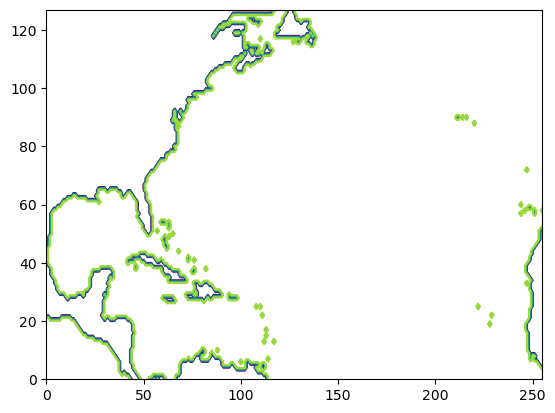

In [24]:
plt.contour(np.nan_to_num(mask0_c_nan)[::4,::4])

In [12]:
dsep = xr.open_zarr(op.join(ddir,"MSQG/E-P.zarr"))

gridp = Grid(dsep, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level", "outer": "lp1"}
                    }
            )

In [17]:
Fu0_x = gridp.interp(gridp.interp(gridp.diff(dsep.E00.chunk({"x":-1}), 
                                             "X", padding="extend")
                                  / Delta, 
                                  "X", padding="extend"
                                 ).chunk({"yG":-1}), 
                     "Y", padding="extend"
                    )
Fu0 = -(Fu0_x 
        + gridp.interp(gridp.interp(gridp.diff(dsep.E10.chunk({"y":-1}), 
                                               "Y", padding="extend")
                                    / Delta, 
                                    "Y", padding="extend"
                                   ).chunk({"xG":-1}), 
                       "X", padding="extend"
                      )
       ).fillna(0.)
Fu1 = -gridp.interp(gridp.diff(dsep.Ediag.chunk({"x":-1}), 
                               "X", padding="extend")
                    / Delta, 
                    "X", padding="extend"
                   ).fillna(0.) / (2*ds.N2)
Fu2 = -(gridp.diff(dsep.E20.chunk({"lp1":-1}), "Z", padding="extend"
                  ) / grid.diff(ds.Zp1, "Z", padding="extend")
       ).fillna(0.)

Fv0_x = gridp.interp(gridp.interp(gridp.diff(dsep.E01.chunk({"x":-1}), 
                                             "X", padding="extend")
                                  / Delta, 
                                  "X", padding="extend"
                                 ).chunk({"yG":-1}), 
                     "Y", padding="extend"
                    )
Fv0 = -(Fv0_x 
        + gridp.interp(gridp.interp(gridp.diff(dsep.E11.chunk({"y":-1}), 
                                               "Y", padding="extend")
                                    / Delta,
                                    "Y", padding="extend"
                                   ).chunk({"xG":-1}),
                       "X", padding="extend"
                      )
       ).fillna(0.)
Fv1 = -gridp.interp(gridp.diff(grid.interp((b/ff).chunk({"lp1":-1})**2, "Z", padding="extend"
                                          ).mean("time").chunk({"y":-1}), 
                               "Y", padding="extend")
                    / Delta, 
                    "Y", padding="extend"
                   ).fillna(0.) / (2*ds.N2) * ff**2
Fv2 = -(gridp.diff(dsep.E21.chunk({"lp1":-1}), "Z", padding="extend"
                  ) / grid.diff(ds.Zp1, "Z", padding="extend")
       ).fillna(0.)

Fu0, Fu1, Fu2

(<xarray.DataArray (level: 5, y: 513, x: 1025)> Size: 11MB
 dask.array<neg, shape=(5, 513, 1025), dtype=float32, chunksize=(1, 513, 1025), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06,
 <xarray.DataArray (y: 513, x: 1025, level: 5)> Size: 21MB
 dask.array<truediv, shape=(513, 1025, 5), dtype=float64, chunksize=(128, 256, 1), chunktype=numpy.ndarray>
 Coordinates:
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0,
 <xarray.DataArray (level: 5, y: 513, x: 1025)> Size: 21MB
 dask.array<neg, shape=(5, 513, 1025), dtype=float64, chunksize=(5, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   *

In [25]:
Fu = (Fu0 + Fu1 + Fu2
     ).isel(level=slice(1,-1)).compute()
Fv = (Fv0 + Fv1 + Fv2
     ).isel(level=slice(1,-1)).compute()
Fu, Fv

(<xarray.DataArray (level: 3, y: 513, x: 1025)> Size: 13MB
 array([[[-2.62882689e-15, -1.23601555e-14, -3.62838150e-14, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-1.09322472e-14, -4.10877815e-14, -1.10874475e-13, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-3.41052700e-14, -1.17750758e-13, -3.05527811e-13, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         ...,
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           6.92858297e-11,  2.14300029e-11,  5.81332452e-12],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           2.92273388e-11,  8.49345760e-12,  2.14080875e-12],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           1.09089682e-11,  2.98185695e-12,  7.19089068e-13]],
 
        [[-1.03426890e-14, -4.89469576e-14, -1.45206330e-13, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [-4.03016903e-14, -

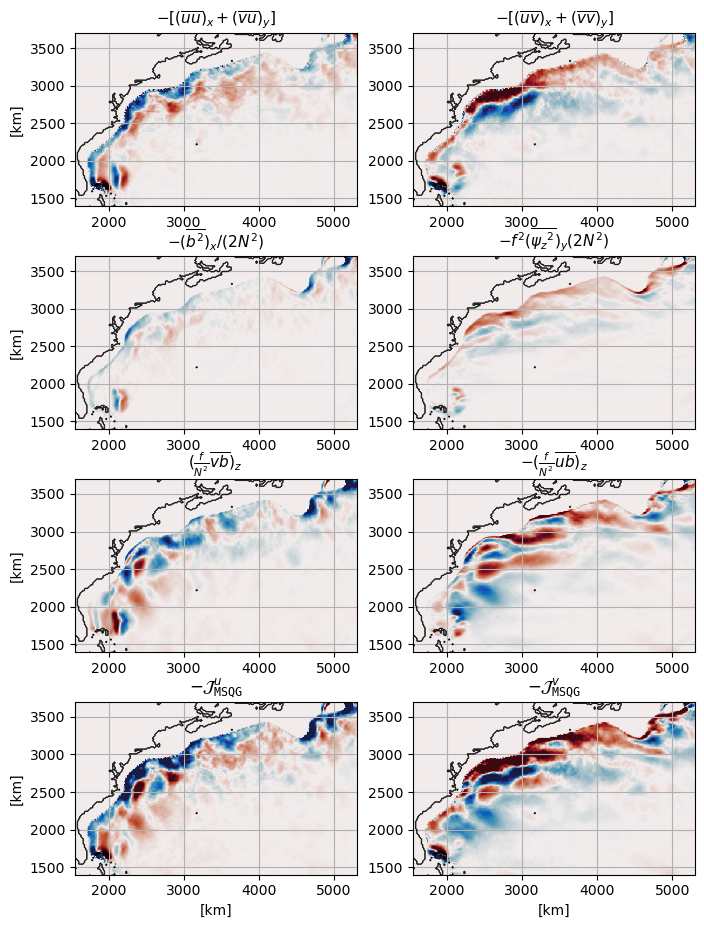

In [28]:
xmax = 5300
xmin = 1550
ymin = 1400
ymax = 3700

fig, axes = plt.subplots(figsize=(8,11.1), nrows=4, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0,0]
ax2 = axes[1,0]
ax3 = axes[2,0]
ax4 = axes[3,0]
ax5 = axes[0,1]
ax6 = axes[1,1]
ax7 = axes[2,1]
ax8 = axes[3,1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax2.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax6.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax6.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax1.coastlines(resolution='110m')
# ax2.coastlines(resolution='110m')
# ax3.coastlines(resolution='110m')
# ax4.coastlines(resolution='110m')
# ax5.coastlines(resolution='110m')
# ax6.coastlines(resolution='110m')
# ax7.coastlines(resolution='110m')
# ax8.coastlines(resolution='110m')
# gl1 = ax1.gridlines(draw_labels=True)
# gl1.top_labels = False
# gl1.right_labels = False
# gl2 = ax2.gridlines(draw_labels=True)
# gl2.top_labels = False
# gl2.right_labels = False
# gl3 = ax3.gridlines(draw_labels=True)
# gl3.top_labels = False
# gl3.right_labels = False
# gl4 = ax4.gridlines(draw_labels=True)
# gl4.top_labels = False
# gl4.right_labels = False
# gl5 = ax5.gridlines(draw_labels=True)
# gl5.top_labels = False
# gl5.right_labels = False
# gl6 = ax6.gridlines(draw_labels=True)
# gl6.top_labels = False
# gl6.right_labels = False
# gl7 = ax7.gridlines(draw_labels=True)
# gl7.top_labels = False
# gl7.right_labels = False
# gl8 = ax8.gridlines(draw_labels=True)
# gl8.top_labels = False
# gl8.right_labels = False

ax1.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax2.pcolormesh(ds.x*1e-3, ds.y*1e-3,
               Fu1.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax3.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu2.isel(level=1) , 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax4.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu.isel(level=0) , 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )

ax5.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
im = ax6.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv1.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
                   )
ax7.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv2.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax8.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )

ax1.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax2.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax3.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax4.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax5.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax6.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax7.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax8.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax1.set_rasterized(True)
ax2.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
ax6.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

ax4.set_xlabel(r"[km]")
ax8.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
ax2.set_ylabel(r"[km]")
ax3.set_ylabel(r"[km]")
ax4.set_ylabel(r"[km]")
ax1.set_aspect("equal")
ax2.set_aspect("equal")
ax3.set_aspect("equal")
ax4.set_aspect("equal")
ax5.set_aspect("equal")
ax6.set_aspect("equal")
ax7.set_aspect("equal")
ax8.set_aspect("equal")
ax1.grid(True)
ax2.grid(True)
ax3.grid(True)
ax4.grid(True)
ax5.grid(True)
ax6.grid(True)
ax7.grid(True)
ax8.grid(True)

ax1.set_title(r"$-[(\overline{uu})_{x} + (\overline{vu})_{y}]$", 
              fontsize=11)
ax2.set_title(r"$-(\overline{{b}^2})_{x}/(2N^2)$", fontsize=11)
ax3.set_title(r"$(\frac{f}{N^2}\overline{vb})_{z}$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt MSQG}$", fontsize=12)

ax5.set_title(r"$-[(\overline{uv})_{x} + (\overline{vv})_{y}]$", 
              fontsize=11)
ax6.set_title(r"$-f^2(\overline{{\psi_z}^2})_{y}(2N^2)$", fontsize=11)
ax7.set_title(r"$-(\frac{f}{N^2}\overline{ub})_{z}$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt MSQG}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_MSQG.pdf"), dpi=200)

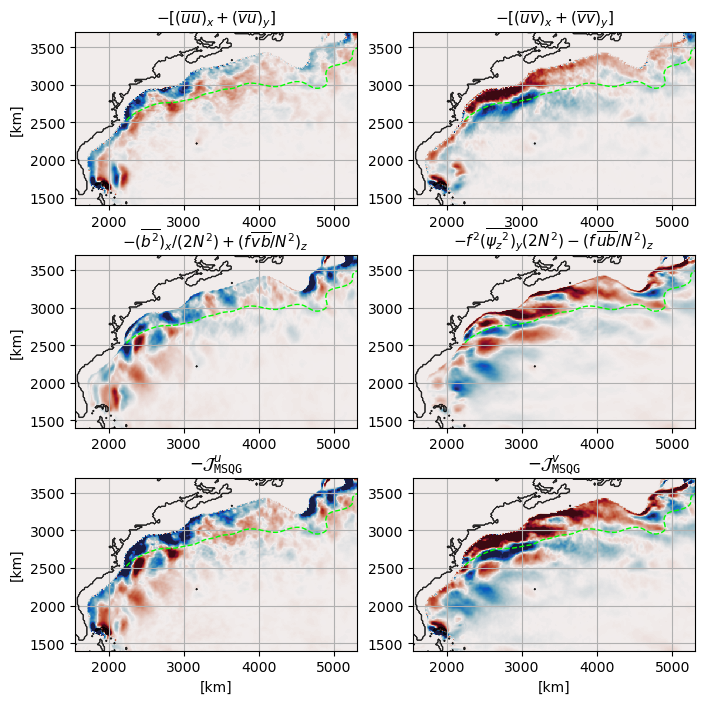

In [34]:
# xmax = 5300
# xmin = 750
# ymin = 1100
# ymax = 3500

fig, axes = plt.subplots(figsize=(8,8.2), nrows=3, ncols=2)
# fig.set_tight_layout(True)
ax1 = axes[0,0]
# ax2 = axes[1,0]
ax3 = axes[1,0]
ax4 = axes[2,0]
ax5 = axes[0,1]
# ax6 = axes[1,1]
ax7 = axes[1,1]
ax8 = axes[2,1]
ax1.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax1.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax2.set_xlim([xmin, xmax], 
#               # crs=ccrs.PlateCarree()
#               )
# ax2.set_ylim([ymin, ymax], 
#               # crs=ccrs.PlateCarree()
#               )
ax3.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax3.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax4.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax5.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax6.set_xlim([xmin, xmax], 
#               # crs=ccrs.PlateCarree()
#               )
# ax6.set_ylim([ymin, ymax], 
#               # crs=ccrs.PlateCarree()
#               )
ax7.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax7.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_xlim([xmin, xmax], 
              # crs=ccrs.PlateCarree()
              )
ax8.set_ylim([ymin, ymax], 
              # crs=ccrs.PlateCarree()
              )
# ax1.coastlines(resolution='110m')
# ax2.coastlines(resolution='110m')
# ax3.coastlines(resolution='110m')
# ax4.coastlines(resolution='110m')
# ax5.coastlines(resolution='110m')
# ax6.coastlines(resolution='110m')
# ax7.coastlines(resolution='110m')
# ax8.coastlines(resolution='110m')
# gl1 = ax1.gridlines(draw_labels=True)
# gl1.top_labels = False
# gl1.right_labels = False
# gl2 = ax2.gridlines(draw_labels=True)
# gl2.top_labels = False
# gl2.right_labels = False
# gl3 = ax3.gridlines(draw_labels=True)
# gl3.top_labels = False
# gl3.right_labels = False
# gl4 = ax4.gridlines(draw_labels=True)
# gl4.top_labels = False
# gl4.right_labels = False
# gl5 = ax5.gridlines(draw_labels=True)
# gl5.top_labels = False
# gl5.right_labels = False
# gl6 = ax6.gridlines(draw_labels=True)
# gl6.top_labels = False
# gl6.right_labels = False
# gl7 = ax7.gridlines(draw_labels=True)
# gl7.top_labels = False
# gl7.right_labels = False
# gl8 = ax8.gridlines(draw_labels=True)
# gl8.top_labels = False
# gl8.right_labels = False

ax1.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
# ax2.pcolormesh(dsp.x*1e-3, dsp.y*1e-3,
#                gridp.interp(Fu1.chunk({"li":-1}), "Z",boundary="extend"
#                            ).isel(level=1) * mask0_nan, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                zorder=0,
#                # rasterized=True
#               )
ax3.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               (Fu2.isel(level=1)
                + Fu1.isel(level=1)), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax4.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )

ax5.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
# im = ax6.pcolormesh(dsp.x*1e-3, dsp.y*1e-3, 
#                gridp.interp(Fv1.chunk({"li":-1}),"Z",boundary="extend"
#                            ).isel(level=1) * mask0_nan, 
#                cmap=cmocean.cm.balance,
#                # cmap="RdBu_r",
#                vmin=-2.4e-6, vmax=2.4e-6,
#                zorder=0,
#                # rasterized=True
#                    )
ax7.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               (Fv2.isel(level=1)
                + Fv1.isel(level=1)), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )
ax8.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fv.isel(level=0), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               zorder=0,
               # rasterized=True
              )

ax1.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax3.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax4.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax5.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax7.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)
ax8.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="lime", linestyles="dashed", linewidths=1)

ax1.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
# ax2.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
#             colors="k", linewidths=.2, zorder=10)
ax3.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax4.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax5.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
# ax6.contour(dsp.x[::2]*1e-3, dsp.y[::2]*1e-3, mask0[::2,::2], 
#             colors="k", linewidths=.2, zorder=10)
ax7.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax8.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)
ax1.set_rasterized(True)
# ax2.set_rasterized(True)
ax3.set_rasterized(True)
ax4.set_rasterized(True)
ax5.set_rasterized(True)
# ax6.set_rasterized(True)
ax7.set_rasterized(True)
ax8.set_rasterized(True)

ax4.set_xlabel(r"[km]")
ax8.set_xlabel(r"[km]")
ax1.set_ylabel(r"[km]")
# ax2.set_ylabel(r"[km]")
ax3.set_ylabel(r"[km]")
ax4.set_ylabel(r"[km]")
ax1.set_aspect("equal")
# ax2.set_aspect("equal")
ax3.set_aspect("equal")
ax4.set_aspect("equal")
ax5.set_aspect("equal")
# ax6.set_aspect("equal")
ax7.set_aspect("equal")
ax8.set_aspect("equal")
ax1.grid(True)
# ax2.grid(True)
ax3.grid(True)
ax4.grid(True)
ax5.grid(True)
# ax6.grid(True)
ax7.grid(True)
ax8.grid(True)

ax1.set_title(r"$-[(\overline{uu})_{x} + (\overline{vu})_{y}]$", 
              fontsize=11)
# ax2.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{x}$", fontsize=11)
ax3.set_title(r"$-(\overline{{b}^2})_{x}/(2N^2) + (f\,\overline{vb}/N^2)_{z}$", 
              fontsize=11)
ax4.set_title(r"$-\mathcal{J}^u_{\tt MSQG}$", fontsize=12)

ax5.set_title(r"$-[(\overline{uv})_{x} + (\overline{vv})_{y}]$", 
              fontsize=11)
# ax6.set_title(r"$-[\overline{{b'}^2}/(2N^2_0)]_{y}$", fontsize=11)
ax7.set_title(r"$-f^2(\overline{{\psi_z}^2})_{y}(2N^2) - (f\,\overline{ub}/N^2)_{z}$", 
              fontsize=11)
ax8.set_title(r"$-\mathcal{J}^v_{\tt MSQG}$", fontsize=12)

# cb = fig.colorbar(im, ax=ax6)
# cb.set_label(r"[m$\,$s$^{-2}$]")

plt.savefig(op.join(ddir,"Figs/E-P_MSQG_added.pdf"), dpi=200)

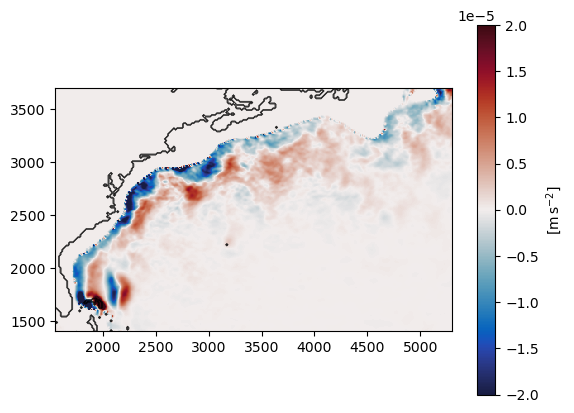

In [30]:
fig = plt.figure()
ax6 = fig.add_subplot(1, 1, 1)
ax6.set_xlim([xmin, xmax], )
ax6.set_ylim([ymin, ymax], )

im = ax6.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               Fu0.isel(level=1), 
               cmap=cmocean.cm.balance,
               # cmap="RdBu_r",
               vmin=-2e-5, vmax=2e-5,
               rasterized=True)

ax6.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax6)
cb.set_label(r"[m$\,$s$^{-2}$]")

ax6.set_rasterized(True)
ax6.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/E-P_MSQG_cbar.pdf"))